In [28]:
from langgraph.graph import StateGraph, START, MessagesState, END
from langchain_ollama import ChatOllama
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import HumanMessage, RemoveMessage # ye use kiya jata hai message ko permanent delete karna k liye
from dotenv import load_dotenv

load_dotenv()

True

In [29]:
llm1 = ChatOllama(model="nemotron-3-nano:30b-cloud")
llm2 = ChatGroq(model="llama-3.3-70b-versatile")
llm3 = ChatOllama(model="smollm2:360m")

In [30]:
final_model = llm1.with_fallbacks(fallbacks=[llm2,llm3])

In [31]:
class ChatState(MessagesState):
    summary: str

In [32]:
def chat_node(state: ChatState):
    messages = []
    if state["summary"]:
        messages.append({
            "role":"system",
            "content":f"Conversation summary:\n{state["summary"]}"
        })

    messages.extend(state["messages"])
    
    print(messages)

    response = final_model.invoke(messages)
    return{
        "messages":response
    }

In [33]:
def summarize_conversation(state: ChatState):
    existing_summary = state["summary"]

    # Build summarization prompt
    if existing_summary:
        prompt = (
            f"Existing summary:\n{existing_summary}\n\n"
            "Extend the summary using the new conversation above."
        )
    else:
        prompt = "Summarize the conversation above."

    messages_for_summary= state["messages"] + [
        HumanMessage(content=prompt)
    ]

    response = final_model.invoke(messages_for_summary)

    # Keep only last 2 message
    message_to_delete = state["messages"][:-2]

    return{
        "summary": response.content,
        "messages": [RemoveMessage(id=m.id) for m in message_to_delete]
    }

In [34]:
def should_summarize(state: ChatState):
    return len(state["messages"]) > 6

In [35]:
workflow = StateGraph(ChatState)
workflow.add_node("chat_node",chat_node)
workflow.add_node("summarize",summarize_conversation)

# edges 
workflow.add_edge(START, "chat_node")
workflow.add_conditional_edges("chat_node",should_summarize,{
    True: "summarize",
    False: END
})
workflow.add_edge("summarize", END)


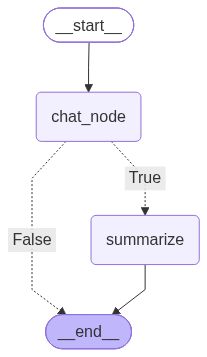

In [36]:
graph = workflow.compile(checkpointer=InMemorySaver())
graph

In [37]:
config = {"configurable": {"thread_id": "t1"}}

In [38]:
# gives the current version of the state
def show_state():
    snap = graph.get_state(config)
    vals = snap.values
    print("\n--- STATE ---")
    print("summary:", vals.get("summary", ""))
    print("num_messages:", len(vals.get("messages", [])))
    print("messages:")
    for m in vals.get("messages", []):
        print("-", type(m).__name__, ":", m.content[:80])

In [39]:
out = graph.invoke({
    "messages": [HumanMessage(content="Quantum Physics")], "summary":""
}, config=config)
print(out)
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='40670c65-f01f-4a31-a2cd-cac181db2b98')]
{'messages': [HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='40670c65-f01f-4a31-a2cd-cac181db2b98'), AIMessage(content='## Quantum Physics – A Concise Overview\n\nQuantum physics (or quantum mechanics) is the branch of physics that describes how matter and energy behave at the smallest scales—atoms, molecules, nuclei, and elementary particles. It departs dramatically from the intuitive “classical” physics that governs our everyday experience.\n\nBelow is a structured snapshot of the field, its core principles, historical milestones, experimental evidence, and modern applications.\n\n---\n\n### 1. Foundational Concepts\n\n| Concept | What It Means | Key Implications |\n|---------|---------------|------------------|\n| **Wave‑Particle Duality** | Particles (e.g., electrons, photons) exhibit both wave‑like and particle‑li

In [40]:
out = graph.invoke({
    "messages": [HumanMessage(content="How is Albert Einstien related?")], "summary":""
}, config=config)
print(out)
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='40670c65-f01f-4a31-a2cd-cac181db2b98'), AIMessage(content='## Quantum Physics – A Concise Overview\n\nQuantum physics (or quantum mechanics) is the branch of physics that describes how matter and energy behave at the smallest scales—atoms, molecules, nuclei, and elementary particles. It departs dramatically from the intuitive “classical” physics that governs our everyday experience.\n\nBelow is a structured snapshot of the field, its core principles, historical milestones, experimental evidence, and modern applications.\n\n---\n\n### 1. Foundational Concepts\n\n| Concept | What It Means | Key Implications |\n|---------|---------------|------------------|\n| **Wave‑Particle Duality** | Particles (e.g., electrons, photons) exhibit both wave‑like and particle‑like behavior. | Interference and diffraction can be observed with single quanta; detection events are discrete. |\n| **Superposition** | A quan

In [41]:
out = graph.invoke({
    "messages": [HumanMessage(content="What are Einstien famous work?")], "summary":""
}, config=config)
print(out)
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='40670c65-f01f-4a31-a2cd-cac181db2b98'), AIMessage(content='## Quantum Physics – A Concise Overview\n\nQuantum physics (or quantum mechanics) is the branch of physics that describes how matter and energy behave at the smallest scales—atoms, molecules, nuclei, and elementary particles. It departs dramatically from the intuitive “classical” physics that governs our everyday experience.\n\nBelow is a structured snapshot of the field, its core principles, historical milestones, experimental evidence, and modern applications.\n\n---\n\n### 1. Foundational Concepts\n\n| Concept | What It Means | Key Implications |\n|---------|---------------|------------------|\n| **Wave‑Particle Duality** | Particles (e.g., electrons, photons) exhibit both wave‑like and particle‑like behavior. | Interference and diffraction can be observed with single quanta; detection events are discrete. |\n| **Superposition** | A quan

In [42]:
out = graph.invoke({
    "messages": [HumanMessage(content="Explain special theroy of relativity")], "summary":""
}, config=config)
print(out)
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='40670c65-f01f-4a31-a2cd-cac181db2b98'), AIMessage(content='## Quantum Physics – A Concise Overview\n\nQuantum physics (or quantum mechanics) is the branch of physics that describes how matter and energy behave at the smallest scales—atoms, molecules, nuclei, and elementary particles. It departs dramatically from the intuitive “classical” physics that governs our everyday experience.\n\nBelow is a structured snapshot of the field, its core principles, historical milestones, experimental evidence, and modern applications.\n\n---\n\n### 1. Foundational Concepts\n\n| Concept | What It Means | Key Implications |\n|---------|---------------|------------------|\n| **Wave‑Particle Duality** | Particles (e.g., electrons, photons) exhibit both wave‑like and particle‑like behavior. | Interference and diffraction can be observed with single quanta; detection events are discrete. |\n| **Superposition** | A quan